In [3]:
import json
import matplotlib.pyplot as plt
import pandas as pd

dataset = 'cic_ids'
dir_path = 'E:/seminar_topic/code/dataset'
# Load config data
with open(f'{dir_path}/{dataset}/noniid/config.json', 'r') as file:
    data = json.load(file)

# create dataframe contains size of samples for lables in each client
clients_data = []
for client_id, samples in enumerate(data['Size of samples for labels in clients']):
    for label, size in samples:
        clients_data.append({'Client': client_id, 'Label': label, 'Size': size})

data = pd.DataFrame(clients_data)
# Pivot the DataFrame
data = data.pivot(index='Client', columns='Label', values='Size').fillna(0)
data.head()

Label,0,1,2,3,4,5,6,7,8,9,10,11
Client,,,,,,,,,,,,
0,194.0,0.0,0.0,0.0,10.0,0.0,80.0,0.0,116.0,0.0,1.0,130.0
1,24.0,515.0,615.0,0.0,0.0,0.0,5297.0,4492.0,0.0,0.0,3241.0,85.0
2,8.0,293.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,4.0,1.0,0.0
3,0.0,0.0,0.0,777.0,0.0,0.0,64391.0,0.0,0.0,0.0,0.0,0.0
4,0.0,11.0,11.0,55.0,0.0,0.0,0.0,1.0,0.0,0.0,25154.0,0.0


In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, FuncFormatter

def visualize_stacked_bar(data, clients_list, dataset):
    if clients_list is not None:
        data = data.loc[clients_list]
        
    # Plot stacked bar chart
    plt.figure(figsize=(2, 4))
    ax = data.plot(kind='bar', stacked=True)
    
    # Tăng kích thước chữ cho tiêu đề trục
    plt.xlabel('Client', fontsize=14)
    plt.ylabel('Sample Size', fontsize=14)
    
    # Giảm kích thước chữ cho tiêu đề của chú giải và các mục trong chú giải
    plt.legend(title='Label', bbox_to_anchor=(1.05, 1), loc='upper left', title_fontsize='14', fontsize='14')
    
    # Đặt nhãn trục x với kích thước chữ lớn hơn
    labels = [f'{i}' for i in clients_list]
    x = [i for i in range(len(clients_list))]
    plt.xticks(x, labels, rotation='vertical', fontsize=14)
    
    # Tăng kích thước chữ cho nhãn trục y
    plt.yticks(fontsize=14)

    # Format lại trục y để hiển thị số 14000 thành 14k
    def thousands_formatter(x, pos):
        return '%1.0fk' % (x * 1e-4)

    ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

    # Tắt các đường tick ở trục x
    plt.tick_params(axis='x', which='both', bottom=False, top=False)
    
    # Điều chỉnh không gian để tăng kích thước phần vẽ
    plt.subplots_adjust(right=0.7)  # Điều chỉnh không gian bên phải để làm cho phần vẽ rộng hơn
    
    plt.tight_layout()
    plt.savefig(f"noniid_cic_ids.png", bbox_inches='tight')
    plt.show()


<Figure size 200x400 with 0 Axes>

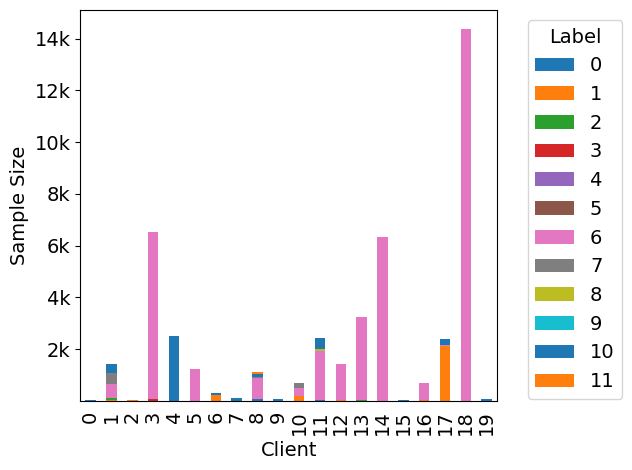

In [19]:
clients_list = [i for i in range(20)]
# clients_list = None
visualize_stacked_bar(data, clients_list, dataset)